# Service window sweep 2 — the cliff, and what causes it

The first two sweeps mapped the service window across the campus map at an
abandonment threshold of 900s:

```
W300   W450   W600   W750   W900  |  W1200   W1800   W2600     ∞
53.7   74.5   83.7   89.6   91.6  |   78.3    79.8    80.1   80.1
```

Coverage peaks **exactly at 900s** — the abandonment threshold — then falls
off a **13.3-point cliff** by 1200s and settles at 80.1%. W2600 reproduced the
unbounded-window column bit-identically, so the window stops binding entirely
somewhere around two fixed-route cycles.

## The explanation on trial

**Triage.** At a window at or below the abandonment threshold, the policy only
ever commits to requests it can actually deliver. Above it, the policy accepts
requests that will abandon before the bus can reach them, routes toward them,
and loses them anyway — and that wasted bus-time comes straight out of the
requests it could have served.

Plausible, but the evidence so far cannot distinguish it from a coincidence.
This notebook runs the two experiments that can.

### Q1 — is the cliff a discontinuity, or a ramp?

Only two points bracket it. If coverage holds at ~91% right up to 900s and
collapses immediately past it, that is a signature of triage: the mechanism
switches on the instant the window exceeds what the passenger will tolerate.
A smooth ramp would suggest something more gradual and less threshold-bound.

**Refuted if** the decline begins *below* 900s — that would mean the peak is
not at the threshold at all, and the whole triage story is wrong.

### Q2 — does the peak follow the threshold?

This is the decisive test, and sweeping the window alone cannot do it. If
900s is special *because it is the abandonment threshold*, then moving the
threshold should move the peak with it. If 900s is special because of the
map's travel geometry, the peak should stay put.

**Confirmed if** curves at thresholds of 600 / 900 / 1200s all peak when the
window equals the threshold. **Refuted if** the peak stays near 900s
regardless.

### Q3 — what is the progress fallback doing?

A loose end from the last run: the 300s column had a *worse* P90 wait (721s)
than the 450s column (552s), which is backwards for a tighter window.

The suspect is `_progress_fallback`. When every request is rejected, the
schedule yields no route and the bus is sent to the nearest pending pickup
**regardless of any window** — otherwise it would sit still forever and the
simulation would deadlock. So a very tight window may not be doing strict
triage at all; it may be degenerating into unwindowed greedy, which is exactly
the thing with a bad wait tail.

Nothing currently measures this. A notebook-local subclass below counts it.

**Refuted if** the fallback rate is flat across window widths — then the W300
anomaly has some other cause.

In [1]:
%matplotlib inline
# Static comparison charts only.

import statistics
from collections import defaultdict

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import summarize_comparison
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.graph import PlanarStreetGraph

# Per-column tallies. Keys are the column labels used below, which must stay
# unique across both sweeps or the counts merge.
PLAN_CALLS: dict[str, int] = defaultdict(int)
FALLBACK_CALLS: dict[str, int] = defaultdict(int)


class CountingWindowInsertionPolicy(WindowInsertionPolicy):
    """
    WindowInsertionPolicy that tallies how often it falls back.

    Behaviourally identical to its parent — both overrides increment a
    counter and delegate straight up, so results are unaffected.
    ``_progress_fallback`` is reachable only from ``plan`` when the schedule
    yields no route, so the ratio of the two counters is the fraction of
    planning calls that degenerated into "drive to the nearest pickup,
    window or no window".
    """

    def __init__(self, graph, label, **kwargs):
        """
        :param graph: Transit graph, forwarded to the parent.
        :param label: Column label these counts are filed under.
        :param kwargs: Any other WindowInsertionPolicy argument.
        """
        super().__init__(graph, **kwargs)
        self._label = label

    def plan(self, state, n_stops):
        """Count the planning call, then plan normally."""
        PLAN_CALLS[self._label] += 1
        return super().plan(state, n_stops)

    def _progress_fallback(self, state):
        """Count the fallback, then fall back normally."""
        FALLBACK_CALLS[self._label] += 1
        return super()._progress_fallback(state)


def make_factory(label, window):
    """
    Build a policy factory bound to one label and one service window.

    A named closure rather than a lambda, so the late-binding trap that
    bites list comprehensions cannot arise.
    :param label: Column label for the counters.
    :param window: Service window in seconds.
    :return: Callable taking a TransitGraph and returning a policy.
    """
    def factory(graph):
        return CountingWindowInsertionPolicy(
            graph, label=label, max_wait_s=window
        )
    return factory

## 1. Shared map

Identical to every previous sweep — same `MAP_SEED`, same campus
configuration — so columns here are directly comparable to earlier runs.

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


## 2. Part A — resolving the cliff

Ten windows between 900 and 1200, spaced tighter at the low end where the
discontinuity is hypothesised, plus four **tight** windows re-measured from
the earlier sweeps.

The tight windows are not padding. Part C needs fallback rates in the region
where the P90 anomaly lives (300–750s), and re-measuring them under identical
settings doubles as a consistency check against the previous run: those four
columns should reproduce their old numbers closely.

`TRIAL_KWARGS` is unchanged, so **everything above 900s is the past-threshold
region** — the policy is accepting riders it cannot deliver.

### Runtime

Part A is 14 columns and Part B another 15, at roughly 1.4s per trial (more
at the 1200s threshold, where more requests stay live). Budget **75–90
minutes** for the whole notebook.

In [3]:
# Dense around the hypothesised discontinuity at 900s.
CLIFF_WINDOWS = [900, 910, 925, 950, 975, 1000, 1050, 1100, 1150, 1200]

# Re-measured from earlier sweeps: extends the curve leftwards and gives
# Part C fallback rates where the P90 anomaly actually is.
TIGHT_WINDOWS = [300, 450, 600, 750]

PART_A_WINDOWS = sorted(TIGHT_WINDOWS + CLIFF_WINDOWS)

N_TRIALS = 100
BASE_SEED = 0

# Unchanged from every previous sweep. max_wait_s is the SIMULATION's
# abandonment threshold, not the policy's window.
TRIAL_KWARGS = dict(max_requests=200, capacity=40, max_wait_s=900.0)


def window_label(window):
    """Column label for a Part A window."""
    return f"W{int(window)}s"


cliff_summary = summarize_comparison(
    policies=[
        (window_label(w), make_factory(window_label(w), float(w)))
        for w in PART_A_WINDOWS
    ],
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    **TRIAL_KWARGS,
)

display(Markdown(cliff_summary.markdown))

W300s :   0%|          | 0/100 [00:00<?, ?it/s]

W450s :   0%|          | 0/100 [00:00<?, ?it/s]

W600s :   0%|          | 0/100 [00:00<?, ?it/s]

W750s :   0%|          | 0/100 [00:00<?, ?it/s]

W900s :   0%|          | 0/100 [00:00<?, ?it/s]

W910s :   0%|          | 0/100 [00:00<?, ?it/s]

... (5 outputs left out)

W1100s:   0%|          | 0/100 [00:00<?, ?it/s]

W1150s:   0%|          | 0/100 [00:00<?, ?it/s]

W1200s:   0%|          | 0/100 [00:00<?, ?it/s]

| Property | W300s | W450s | W600s | W750s | W900s | W910s | W925s | W950s | W975s | W1000s | W1050s | W1100s | W1150s | W1200s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 105.3 (±2.6%) | 147.0 (±2.3%) | 165.4 (±2.2%) | 177.1 (±2.1%) | 181.2 (±2.0%) | 176.1 (±2.1%) | 170.8 (±2.1%) | 165.7 (±2.1%) | 160.4 (±2.2%) | 158.1 (±2.2%) | 155.8 (±2.1%) | 155.1 (±2.2%) | 153.9 (±2.2%) | 154.6 (±2.2%) |
| Cancelled requests | 92.7 (±2.8%) | 51.0 (±3.8%) | 32.6 (±4.7%) | 20.9 (±5.0%) | 16.8 (±5.5%) | 21.9 (±5.9%) | 27.2 (±4.8%) | 32.4 (±4.5%) | 37.6 (±4.2%) | 39.9 (±4.2%) | 42.2 (±3.6%) | 42.9 (±3.9%) | 44.1 (±3.5%) | 43.4 (±3.6%) |
| Mean wait time | 355.3 s (±2.3%) | 353.0 s (±2.1%) | 400.7 s (±2.1%) | 446.9 s (±2.1%) | 494.4 s (±2.1%) | 482.5 s (±2.2%) | 468.7 s (±2.1%) | 456.8 s (±2.1%) | 446.3 s (±2.1%) | 445.0 s (±2.2%) | 436.6 s (±2.1%) | 430.0 s (±2.2%) | 430.6 s (±2.2%) | 424.9 s (±2.2%) |
| P90 wait time | 721.0 s (±2.3%) | 551.9 s (±2.9%) | 585.6 s (±2.0%) | 722.0 s (±2.0%) | 850.1 s (±2.0%) | 839.5 s (±2.0%) | 828.0 s (±2.0%) | 811.1 s (±2.0%) | 797.9 s (±2.1%) | 791.3 s (±2.1%) | 781.3 s (±2.1%) | 773.0 s (±2.1%) | 772.9 s (±2.1%) | 765.2 s (±2.1%) |
| Mean ride time | 410.8 s (±3.7%) | 822.6 s (±3.3%) | 778.3 s (±3.4%) | 630.7 s (±3.0%) | 541.2 s (±3.0%) | 527.7 s (±2.9%) | 514.8 s (±3.1%) | 507.5 s (±2.9%) | 495.2 s (±2.7%) | 476.8 s (±2.8%) | 460.9 s (±2.6%) | 446.7 s (±2.5%) | 433.4 s (±2.5%) | 419.1 s (±2.4%) |
| Fulfillment rate | 53.7 % (±2.4%) | 74.5 % (±1.3%) | 83.7 % (±0.9%) | 89.6 % (±0.6%) | 91.6 % (±0.5%) | 89.0 % (±0.7%) | 86.4 % (±0.8%) | 83.8 % (±0.9%) | 81.2 % (±1.0%) | 80.0 % (±1.1%) | 78.9 % (±1.0%) | 78.5 % (±1.1%) | 77.9 % (±1.0%) | 78.3 % (±1.0%) |
| Served fraction | 53.7 % (±2.4%) | 74.5 % (±1.3%) | 83.7 % (±0.9%) | 89.6 % (±0.6%) | 91.6 % (±0.5%) | 89.0 % (±0.7%) | 86.4 % (±0.8%) | 83.8 % (±0.9%) | 81.2 % (±1.0%) | 80.0 % (±1.1%) | 78.9 % (±1.0%) | 78.5 % (±1.1%) | 77.9 % (±1.0%) | 78.3 % (±1.0%) |
| Throughput | 0.5 req/min (±4.8%) | 0.7 req/min (±3.0%) | 0.8 req/min (±2.5%) | 0.8 req/min (±2.1%) | 0.8 req/min (±2.1%) | 0.8 req/min (±2.2%) | 0.8 req/min (±2.3%) | 0.8 req/min (±2.5%) | 0.7 req/min (±2.6%) | 0.7 req/min (±2.7%) | 0.7 req/min (±2.7%) | 0.7 req/min (±2.8%) | 0.7 req/min (±2.8%) | 0.7 req/min (±2.7%) |
| Tick snapshots | 12715.6 (±2.0%) | 12914.9 (±2.0%) | 13011.2 (±2.0%) | 13046.8 (±2.0%) | 13091.7 (±2.0%) | 13062.9 (±2.0%) | 13057.0 (±2.0%) | 13033.4 (±2.0%) | 13000.4 (±2.0%) | 12962.5 (±2.0%) | 12978.0 (±2.0%) | 12987.1 (±2.0%) | 12921.7 (±2.0%) | 12901.9 (±2.0%) |
| Fulfilled (wait samples) | 105.3 (±2.6%) | 147.0 (±2.3%) | 165.4 (±2.2%) | 177.1 (±2.1%) | 181.2 (±2.0%) | 176.1 (±2.1%) | 170.8 (±2.1%) | 165.7 (±2.1%) | 160.4 (±2.2%) | 158.1 (±2.2%) | 155.8 (±2.1%) | 155.1 (±2.2%) | 153.9 (±2.2%) | 154.6 (±2.2%) |
| Min wait time | 8.5 s (±20.3%) | 6.8 s (±20.3%) | 7.2 s (±20.6%) | 6.1 s (±21.5%) | 7.2 s (±23.8%) | 6.0 s (±19.7%) | 5.0 s (±22.6%) | 5.4 s (±21.3%) | 7.2 s (±20.4%) | 5.8 s (±25.6%) | 5.8 s (±21.2%) | 6.7 s (±22.8%) | 4.7 s (±22.3%) | 6.3 s (±24.4%) |
| Max wait time | 876.3 s (±2.0%) | 864.8 s (±2.1%) | 854.2 s (±2.1%) | 856.2 s (±2.1%) | 888.4 s (±2.0%) | 888.2 s (±2.0%) | 888.1 s (±2.0%) | 886.4 s (±2.0%) | 886.1 s (±2.0%) | 884.6 s (±2.0%) | 883.3 s (±2.0%) | 882.2 s (±2.0%) | 883.5 s (±2.0%) | 883.1 s (±2.0%) |
| Min ride time | 10.9 s (±14.2%) | 7.8 s (±12.8%) | 7.7 s (±13.7%) | 6.6 s (±12.6%) | 7.4 s (±14.3%) | 6.6 s (±12.9%) | 6.9 s (±12.2%) | 7.2 s (±13.0%) | 7.1 s (±13.9%) | 6.7 s (±12.4%) | 7.3 s (±14.3%) | 6.9 s (±11.9%) | 7.2 s (±12.3%) | 6.8 s (±13.2%) |
| Max ride time | 1915.5 s (±6.6%) | 4037.1 s (±4.6%) | 4127.0 s (±5.6%) | 3307.0 s (±4.8%) | 2765.3 s (±5.2%) | 2746.6 s (±5.3%) | 2624.5 s (±5.3%) | 2583.7 s (±4.8%) | 2464.3 s (±5.0%) | 2328.6 s (±4.8%) | 2174.2 s (±4.6%) | 2115.7 s (±4.6%) | 2035.7 s (±5.1%) | 1847.1 s (±4.8%) |

## 3. Part A plots

Previously measured windows outside this run (1800s, 2600s) and the two
anchor policies are carried in as a hardcoded reference rather than
re-simulated.

> ⚠️ These came from **100-trial** runs. If a larger run supersedes them,
> update `REFERENCE` — it feeds the plots and nothing else depends on it.

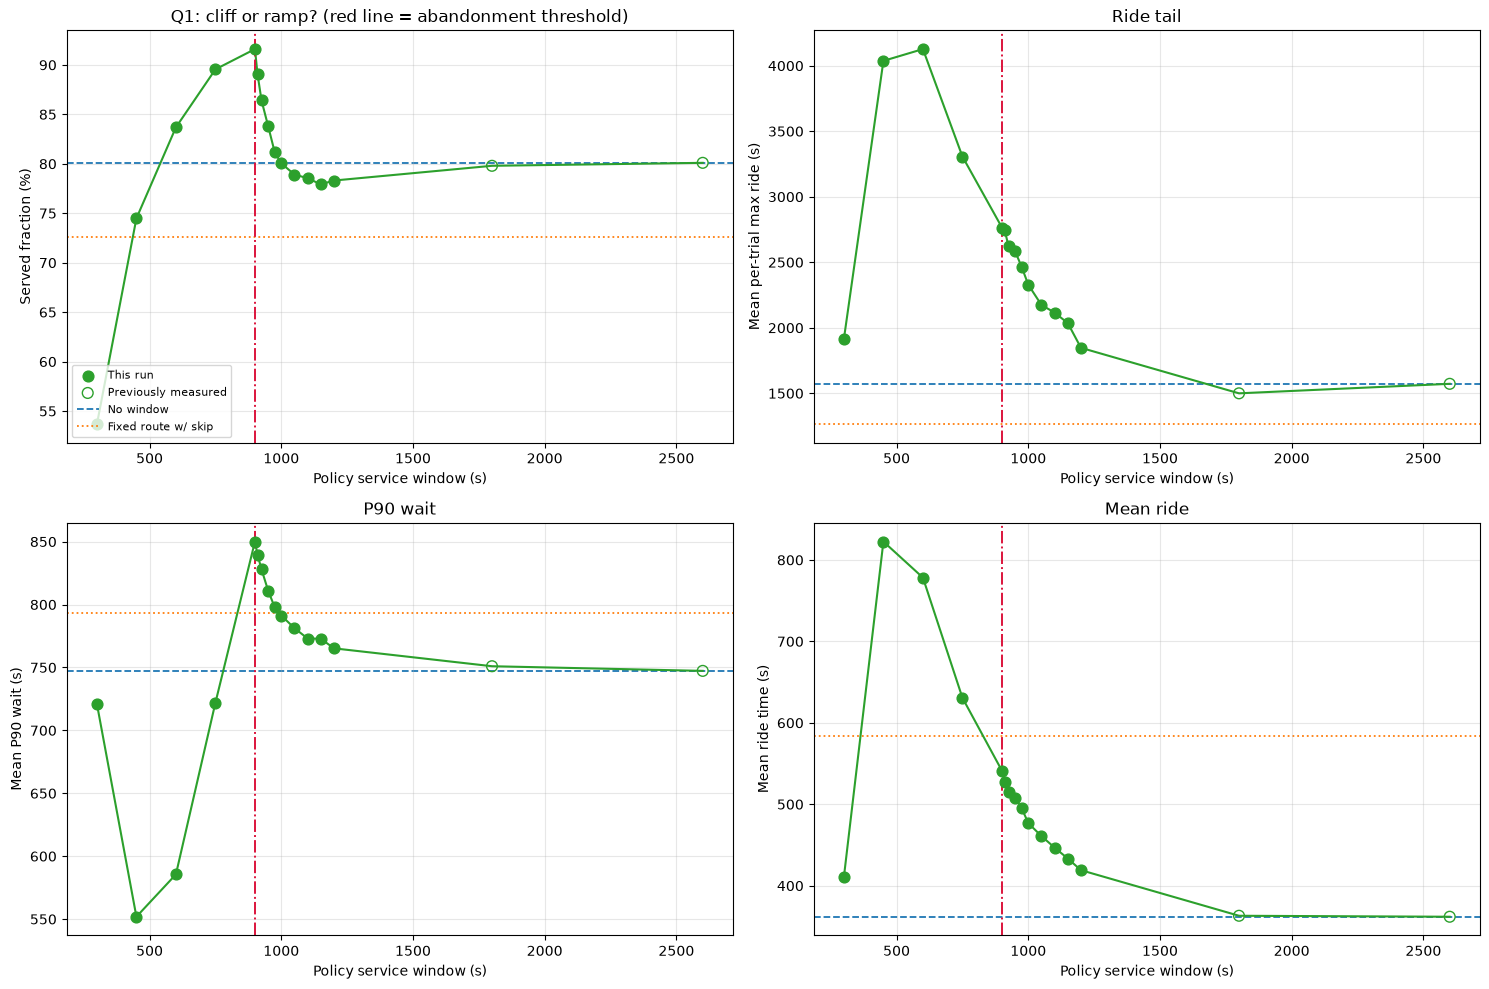

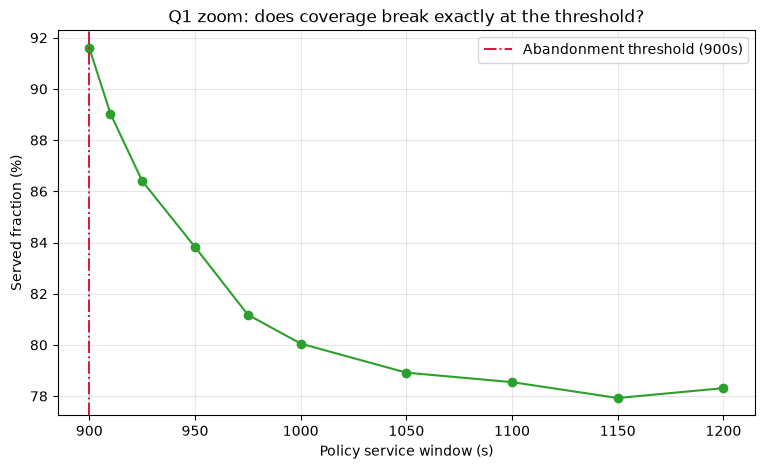

In [4]:
# Previously measured. served is a percentage; every time is seconds.
REFERENCE = {
    1800.0: dict(served=79.8, mean_wait=415.7, p90_wait=751.0,
                 mean_ride=363.1, max_ride=1499.8),
    2600.0: dict(served=80.1, mean_wait=413.6, p90_wait=747.3,
                 mean_ride=361.9, max_ride=1572.4),
}

ANCHORS = {
    "No window": dict(served=80.1, mean_wait=413.6, p90_wait=747.3,
                      mean_ride=361.9, max_ride=1572.4),
    "Fixed route w/ skip": dict(served=72.6, mean_wait=460.4, p90_wait=793.2,
                                mean_ride=583.3, max_ride=1263.9),
}

ABANDON_S = TRIAL_KWARGS["max_wait_s"]


def mean_of(trials, extract):
    """Mean of extract() over trials, skipping runs where it is undefined."""
    values = [v for v in (extract(t) for t in trials) if v is not None]
    return statistics.fmean(values) if values else None


METRICS = {
    "served": lambda ts: (
        None if mean_of(ts, lambda t: t.kpi.served_fraction) is None
        else mean_of(ts, lambda t: t.kpi.served_fraction) * 100.0
    ),
    "mean_wait": lambda ts: mean_of(ts, lambda t: t.kpi.mean_wait_time),
    "p90_wait": lambda ts: mean_of(ts, lambda t: t.kpi.p90_wait_time),
    "mean_ride": lambda ts: mean_of(ts, lambda t: t.kpi.mean_ride_time),
    "max_ride": lambda ts: mean_of(
        ts, lambda t: max(t.ride_times) if t.ride_times else None
    ),
}

measured = {
    float(w): {
        name: extract(cliff_summary.results[window_label(w)])
        for name, extract in METRICS.items()
    }
    for w in PART_A_WINDOWS
}
combined = {**REFERENCE, **measured}


def plot_metric(ax, metric, ylabel, title):
    """Plot one metric against window width, this run plus reference."""
    widths = [
        w for w in sorted(combined) if combined[w][metric] is not None
    ]
    ax.plot(widths, [combined[w][metric] for w in widths], "-",
            color="tab:green", zorder=2)
    ax.scatter([w for w in widths if w in measured],
               [combined[w][metric] for w in widths if w in measured],
               marker="o", color="tab:green", s=60, zorder=3,
               label="This run")
    ax.scatter([w for w in widths if w not in measured],
               [combined[w][metric] for w in widths if w not in measured],
               marker="o", facecolors="none", edgecolors="tab:green", s=60,
               zorder=3, label="Previously measured")
    for name, colour, style in (("No window", "tab:blue", "--"),
                                ("Fixed route w/ skip", "tab:orange", ":")):
        ax.axhline(ANCHORS[name][metric], color=colour, linestyle=style,
                   linewidth=1.3, label=name, zorder=1)
    ax.axvline(ABANDON_S, color="crimson", linestyle="-.", linewidth=1.4)
    ax.set_xlabel("Policy service window (s)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plot_metric(axes[0][0], "served", "Served fraction (%)",
            "Q1: cliff or ramp? (red line = abandonment threshold)")
plot_metric(axes[0][1], "max_ride", "Mean per-trial max ride (s)",
            "Ride tail")
plot_metric(axes[1][0], "p90_wait", "Mean P90 wait (s)", "P90 wait")
plot_metric(axes[1][1], "mean_ride", "Mean ride time (s)", "Mean ride")
axes[0][0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

# Zoom on the cliff itself, where the discontinuity would show.
fig, ax = plt.subplots(figsize=(9, 5))
zoom = [w for w in sorted(measured) if 850 <= w <= 1250]
ax.plot(zoom, [measured[w]["served"] for w in zoom], "-o", color="tab:green")
ax.axvline(ABANDON_S, color="crimson", linestyle="-.", linewidth=1.4,
           label="Abandonment threshold (900s)")
ax.set_xlabel("Policy service window (s)")
ax.set_ylabel("Served fraction (%)")
ax.set_title("Q1 zoom: does coverage break exactly at the threshold?")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## 4. Part B — does the peak follow the threshold?

The decisive experiment. Three abandonment thresholds, each with the window
swept at the same *ratios* of it, so the three curves can be overlaid.

**Why this needs three separate runs.** The abandonment threshold is a
property of the *simulation*, passed to `run_trial` as `max_wait_s` — not a
property of the policy. `summarize_comparison` forwards one set of trial
kwargs to every column it runs, so a threshold cannot be a column. Each
threshold gets its own call, and the results are merged afterwards.

**Read the peak location, not the height.** Absolute served fractions are not
comparable across thresholds: a more patient passenger population means fewer
requests abandon no matter what the policy does, so the 1200s curve will sit
above the 600s curve regardless. The question is only *where each curve
peaks*.

In [5]:
THRESHOLDS = [600.0, 900.0, 1200.0]
RATIOS = [0.5, 0.75, 1.0, 1.25, 1.5]


def ratio_label(threshold, ratio):
    """Column label for one (threshold, ratio) cell."""
    return f"A{int(threshold)} r{ratio:.2f}"


track_results = {}
track_tables = {}

for threshold in THRESHOLDS:
    summary = summarize_comparison(
        policies=[
            (
                ratio_label(threshold, r),
                make_factory(ratio_label(threshold, r), threshold * r),
            )
            for r in RATIOS
        ],
        graph=graph,
        n_trials=N_TRIALS,
        base_seed=BASE_SEED,
        max_requests=200,
        capacity=40,
        # The variable under test: the simulation's abandonment threshold.
        max_wait_s=threshold,
    )
    track_tables[threshold] = summary.markdown
    for r in RATIOS:
        track_results[(threshold, r)] = summary.results[
            ratio_label(threshold, r)
        ]

for threshold in THRESHOLDS:
    display(Markdown(f"### Abandonment threshold {int(threshold)}s"))
    display(Markdown(track_tables[threshold]))

A600 r0.50:   0%|          | 0/100 [00:00<?, ?it/s]

A600 r0.75:   0%|          | 0/100 [00:00<?, ?it/s]

A600 r1.00:   0%|          | 0/100 [00:00<?, ?it/s]

A600 r1.25:   0%|          | 0/100 [00:00<?, ?it/s]

A600 r1.50:   0%|          | 0/100 [00:00<?, ?it/s]

A900 r0.50:   0%|          | 0/100 [00:00<?, ?it/s]

... (11 outputs left out)

### Abandonment threshold 900s

| Property | A900 r0.50 | A900 r0.75 | A900 r1.00 | A900 r1.25 | A900 r1.50 |
| --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 147.0 (±2.3%) | 172.3 (±2.1%) | 181.2 (±2.0%) | 154.2 (±2.2%) | 154.1 (±2.2%) |
| Cancelled requests | 51.0 (±3.8%) | 25.7 (±4.9%) | 16.8 (±5.5%) | 43.8 (±3.7%) | 43.9 (±3.9%) |
| Mean wait time | 353.0 s (±2.1%) | 425.7 s (±2.1%) | 494.4 s (±2.1%) | 432.3 s (±2.1%) | 420.9 s (±2.2%) |
| P90 wait time | 551.9 s (±2.9%) | 655.1 s (±2.0%) | 850.1 s (±2.0%) | 774.2 s (±2.1%) | 760.1 s (±2.1%) |
| Mean ride time | 822.6 s (±3.3%) | 714.7 s (±3.3%) | 541.2 s (±3.0%) | 441.4 s (±2.7%) | 391.6 s (±2.6%) |
| Fulfillment rate | 74.5 % (±1.3%) | 87.1 % (±0.7%) | 91.6 % (±0.5%) | 78.1 % (±1.0%) | 78.0 % (±1.1%) |
| Served fraction | 74.5 % (±1.3%) | 87.1 % (±0.7%) | 91.6 % (±0.5%) | 78.1 % (±1.0%) | 78.0 % (±1.1%) |
| Throughput | 0.7 req/min (±3.0%) | 0.8 req/min (±2.3%) | 0.8 req/min (±2.1%) | 0.7 req/min (±2.8%) | 0.7 req/min (±2.8%) |
| Tick snapshots | 12914.9 (±2.0%) | 13034.2 (±2.0%) | 13091.7 (±2.0%) | 12951.8 (±2.0%) | 12897.2 (±2.0%) |
| Fulfilled (wait samples) | 147.0 (±2.3%) | 172.3 (±2.1%) | 181.2 (±2.0%) | 154.2 (±2.2%) | 154.1 (±2.2%) |
| Min wait time | 6.8 s (±20.3%) | 6.2 s (±19.8%) | 7.2 s (±23.8%) | 6.1 s (±18.1%) | 6.5 s (±17.8%) |
| Max wait time | 864.8 s (±2.1%) | 854.7 s (±2.1%) | 888.4 s (±2.0%) | 882.8 s (±2.0%) | 880.6 s (±2.0%) |
| Min ride time | 7.8 s (±12.8%) | 7.0 s (±13.1%) | 7.4 s (±14.3%) | 8.0 s (±13.4%) | 6.5 s (±10.5%) |
| Max ride time | 4037.1 s (±4.6%) | 3772.5 s (±5.2%) | 2765.3 s (±5.2%) | 2028.3 s (±4.4%) | 1667.7 s (±5.4%) |

### Abandonment threshold 1200s

| Property | A1200 r0.50 | A1200 r0.75 | A1200 r1.00 | A1200 r1.25 | A1200 r1.50 |
| --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 172.9 (±2.1%) | 187.7 (±2.0%) | 192.4 (±2.0%) | 178.0 (±2.1%) | 179.7 (±2.0%) |
| Cancelled requests | 25.1 (±5.0%) | 10.3 (±7.6%) | 5.7 (±10.6%) | 20.0 (±5.3%) | 18.3 (±5.0%) |
| Mean wait time | 428.8 s (±2.2%) | 511.7 s (±2.2%) | 562.8 s (±2.2%) | 505.3 s (±2.2%) | 489.2 s (±2.2%) |
| P90 wait time | 629.8 s (±2.6%) | 864.8 s (±2.0%) | 1081.7 s (±2.1%) | 957.2 s (±2.2%) | 937.3 s (±2.2%) |
| Mean ride time | 781.4 s (±3.5%) | 542.3 s (±3.1%) | 438.0 s (±2.5%) | 394.7 s (±2.5%) | 380.6 s (±2.4%) |
| Fulfillment rate | 87.4 % (±0.7%) | 94.8 % (±0.4%) | 97.2 % (±0.3%) | 90.0 % (±0.6%) | 90.8 % (±0.5%) |
| Served fraction | 87.4 % (±0.7%) | 94.8 % (±0.4%) | 97.2 % (±0.3%) | 90.0 % (±0.6%) | 90.8 % (±0.5%) |
| Throughput | 0.8 req/min (±2.3%) | 0.9 req/min (±1.9%) | 0.9 req/min (±1.8%) | 0.8 req/min (±2.1%) | 0.8 req/min (±2.0%) |
| Tick snapshots | 13085.0 (±2.0%) | 13119.3 (±2.0%) | 13142.3 (±2.0%) | 13031.9 (±2.0%) | 12971.3 (±2.0%) |
| Fulfilled (wait samples) | 172.9 (±2.1%) | 187.7 (±2.0%) | 192.4 (±2.0%) | 178.0 (±2.1%) | 179.7 (±2.0%) |
| Min wait time | 8.4 s (±20.8%) | 7.6 s (±20.4%) | 6.5 s (±20.4%) | 5.0 s (±21.0%) | 5.3 s (±20.3%) |
| Max wait time | 1148.3 s (±2.1%) | 1116.9 s (±2.2%) | 1184.7 s (±2.0%) | 1171.6 s (±2.0%) | 1170.6 s (±2.0%) |
| Min ride time | 7.0 s (±13.4%) | 6.8 s (±12.8%) | 6.5 s (±12.9%) | 6.3 s (±12.1%) | 6.3 s (±11.8%) |
| Max ride time | 4203.0 s (±5.0%) | 2778.6 s (±4.9%) | 1950.0 s (±4.2%) | 1619.3 s (±4.4%) | 1625.0 s (±4.2%) |

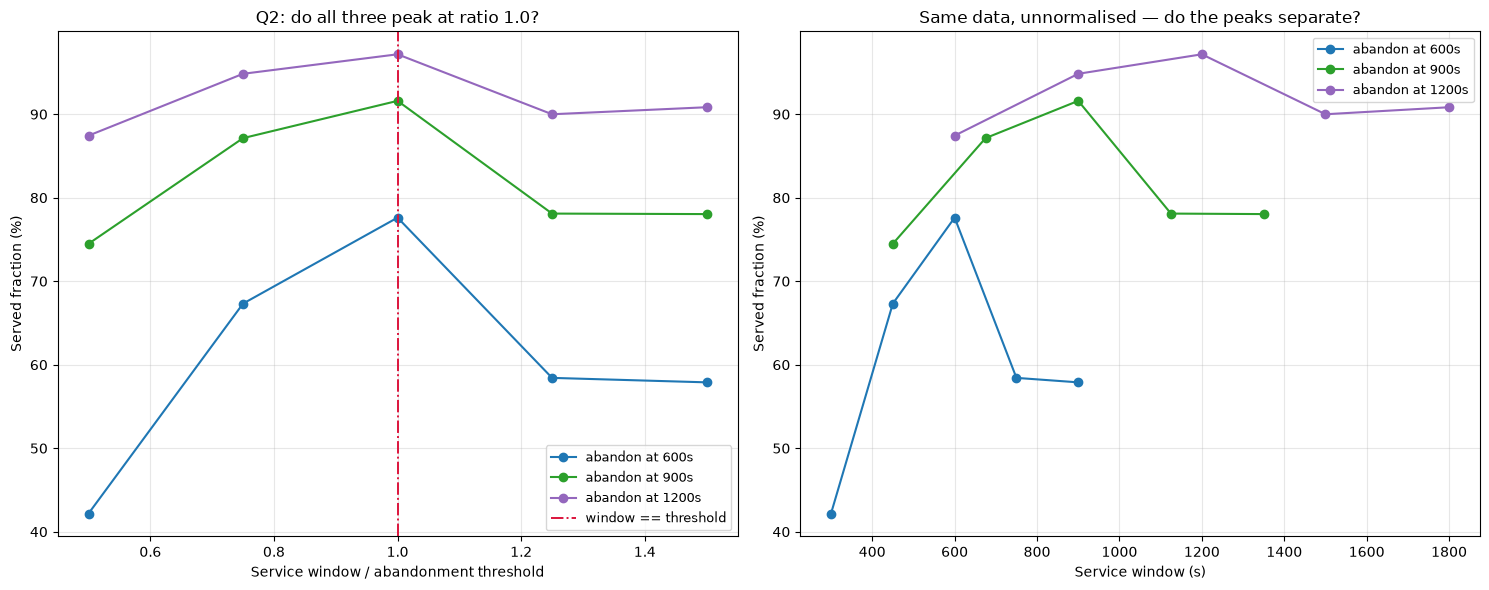

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 6))

for threshold, colour in zip(THRESHOLDS,
                             ["tab:blue", "tab:green", "tab:purple"]):
    served = [
        METRICS["served"](track_results[(threshold, r)]) for r in RATIOS
    ]
    left.plot(RATIOS, served, "-o", color=colour,
              label=f"abandon at {int(threshold)}s")
    right.plot([threshold * r for r in RATIOS], served, "-o", color=colour,
               label=f"abandon at {int(threshold)}s")

left.axvline(1.0, color="crimson", linestyle="-.", linewidth=1.4,
             label="window == threshold")
left.set_xlabel("Service window / abandonment threshold")
left.set_ylabel("Served fraction (%)")
left.set_title("Q2: do all three peak at ratio 1.0?")
left.grid(True, alpha=0.3)
left.legend(fontsize=9)

right.set_xlabel("Service window (s)")
right.set_ylabel("Served fraction (%)")
right.set_title("Same data, unnormalised — do the peaks separate?")
right.grid(True, alpha=0.3)
right.legend(fontsize=9)

plt.tight_layout()
plt.show()

## 5. Part C — how often does the fallback fire?

Every column above ran through `CountingWindowInsertionPolicy`, so the rates
come free. The rate is fallback calls as a fraction of all planning calls: it
is the share of the run during which the policy was **not** doing windowed
insertion at all, but driving to the nearest pickup with the window ignored.

If the tight-window columns show a high rate, then "tight window" does not
mean "strict triage" — it means "reject everything, then behave greedily
anyway", and the W300 P90 anomaly is explained.

| Window | Plan calls | Fallbacks | Fallback rate |
| --- | --- | --- | --- |
| 300s | 13,360 | 957 | 7.2 % |
| 450s | 15,772 | 326 | 2.1 % |
| 600s | 17,276 | 313 | 1.8 % |
| 750s | 18,692 | 313 | 1.7 % |
| 900s | 19,316 | 314 | 1.6 % |
| 910s | 19,308 | 313 | 1.6 % |
| 925s | 19,364 | 312 | 1.6 % |
| 950s | 19,307 | 311 | 1.6 % |
| 975s | 19,256 | 305 | 1.6 % |
| 1000s | 19,229 | 302 | 1.6 % |
| 1050s | 19,184 | 296 | 1.5 % |
| 1100s | 19,199 | 296 | 1.5 % |
| 1150s | 19,147 | 280 | 1.5 % |
| 1200s | 19,250 | 274 | 1.4 % |

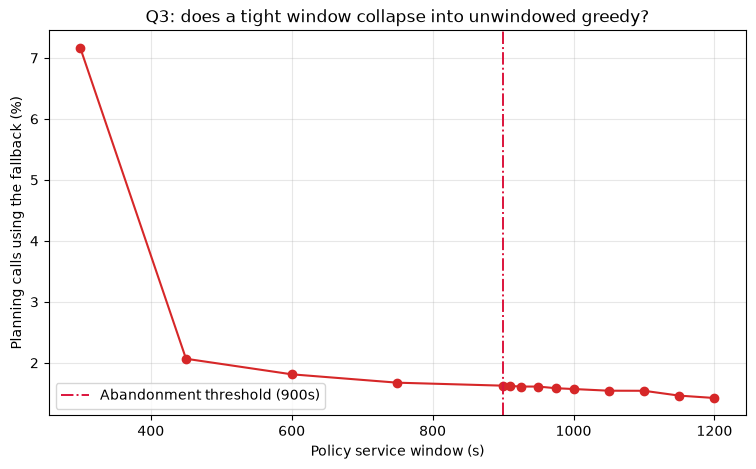

In [7]:
def fallback_pct(label):
    """
    Share of planning calls that fell back, as a percentage.

    Returns NaN rather than None when a column never planned, so the table
    and the plot degrade gracefully instead of raising at the very end of a
    long run. In practice every column plans at least once.
    """
    calls = PLAN_CALLS.get(label, 0)
    if calls == 0:
        return float("nan")
    return 100.0 * FALLBACK_CALLS.get(label, 0) / calls


rows = [
    f"| {int(w)}s | {PLAN_CALLS[window_label(w)]:,} | "
    f"{FALLBACK_CALLS[window_label(w)]:,} | "
    f"{fallback_pct(window_label(w)):.1f} % |"
    for w in PART_A_WINDOWS
]
display(Markdown(
    "| Window | Plan calls | Fallbacks | Fallback rate |\n"
    "| --- | --- | --- | --- |\n" + "\n".join(rows)
))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(PART_A_WINDOWS,
        [fallback_pct(window_label(w)) for w in PART_A_WINDOWS],
        "-o", color="tab:red")
ax.axvline(ABANDON_S, color="crimson", linestyle="-.", linewidth=1.4,
           label="Abandonment threshold (900s)")
ax.set_xlabel("Policy service window (s)")
ax.set_ylabel("Planning calls using the fallback (%)")
ax.set_title("Q3: does a tight window collapse into unwindowed greedy?")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## What to look for

All three questions can come out against the proposed explanations. That is
the point of running this.

**Q1 — cliff or ramp.** The zoom plot is the one to read.

- *Discontinuity at the threshold* → served fraction holds near 91% at 900
  and 910, then breaks sharply by 925–950. Strong support for triage: the
  mechanism switches on the moment the window exceeds passenger patience.
- *Smooth ramp* → a steady decline across all ten points, with nothing special
  happening at 900. Triage would then be at best a partial explanation.
- *Decline starting below 900* → **refutes triage outright.** The peak would
  not be at the threshold, and the coincidence we built the story on would be
  a misreading of a coarse sweep.

**Q2 — does the peak follow the threshold?** The normalised plot is decisive.

- *All three curves peak at ratio 1.0* → triage confirmed. The design rule
  "set the service window equal to the abandonment threshold" is causal, not
  a fluke of this map, and should transfer to any map and any patience level.
- *Peaks pinned near 900s in the unnormalised plot* → the explanation is
  geometric. Something about travel times on this map makes ~900s the right
  window, and the match with the abandonment threshold is coincidence.
- *Peaks somewhere other than 1.0 but consistent across thresholds* (say all
  at 0.9) → triage is roughly right but the policy is systematically
  over-optimistic about what it can deliver, which would point at the
  feasibility projection rather than the concept.

**Q3 — the fallback.** Expect a rate rising steeply as the window tightens
and near zero from 900s upward. That would confirm the tight end of every
sweep so far has been measuring a hybrid policy, not strict triage — and it
would mean the W300 column should be read as "mostly greedy" rather than
"very selective". A flat rate refutes it and sends the P90 anomaly back to
the drawing board.

**Also worth reading off:** the four re-measured tight windows (300 / 450 /
600 / 750) should reproduce their earlier numbers closely. If they do not,
something is less reproducible than the exact W2600 match suggested, and that
matters more than any of the three questions above.

### A caveat on reproducibility

Re-running in a fresh kernel can shift numbers slightly: Python randomizes
string hashing per process, and several policies break ties with `min()` over
a `set[str]`. `WindowInsertionPolicy` appears to be immune — its set
iteration feeds order-independent removals, and it reproduced exactly across
processes — but set `PYTHONHASHSEED=0` before launching Jupyter if you want
that guaranteed rather than observed.